# BIOT 6900 · Module 4 Assignment: Structure-Based Druggability of Your Targets

**Computational Lab 4 · 100 points · due Thursday, October 22 at 6:00 pm**

Apply the Module 4 lab skills to **two targets from your own Module 2 list**. Each step below matches a numbered step on the assignment sheet. Complete every cell marked **TODO**; helper functions from lab Part 2 and the demo are provided so you can focus on the analysis.

**Before you start:** complete lab Parts 1 and 2. Steps 2, 5 and 6 need internet. Step 6 needs **fpocket** (Mac/Linux: `conda install -c conda-forge fpocket`; Windows: run this notebook on the Explorer cluster).

**Run it in Jupyter or VS Code's notebook view**, not as a script. Before submitting: Kernel → Restart & Run All.

## Your settings (Step 1 · Choose two targets)

Pick two **protein-coding** targets from your Module 2 list, ideally **at least one with an experimental structure** (check the "Structure" section of the UniProt entry), each **shorter than 2,700 residues**.

For each target with a PDB structure, give the PDB ID and the chain to use. Use `None` if there is no experimental structure.

In [1]:
DISEASE = "ad"            # Alzheimer's disease, as in Modules 2 and 3

TARGETS = {               # gene symbol -> UniProt accession
    "ITGAX": "P20702",
    "APLNR": "P35414",
}
TARGET_INFO = {           # Module 2 rank and why each target
    "ITGAX": {"module2_rank": 6, "why": "CD11c marks the microglia that gather around AD plaques, and its I domain is drugged by small molecules in the related integrin LFA-1 (ITGAL), so Module 3 flagged it to test for a comparable pocket."},
    "APLNR": {"module2_rank": 10, "why": "A class A GPCR with my strongest Module 3 small-molecule prior (p_sm 0.68) and crystal structures with a small-molecule agonist bound, so the predicted pocket can be checked against a real ligand."},
}
PDB = {                   # gene -> (PDB ID, chain)
    "ITGAX": ("4NEH", "A"),   # alphaX beta2 ectodomain, 2.75 A: the best-resolved entry covering most of ITGAX (1,084 residues); no drug-like ligand
    "APLNR": ("7SUS", "A"),   # apelin receptor crystal, 2.7 A, small-molecule agonist (ligand 8EH) bound; rubredoxin inserted in ICL3
}


In [2]:
import json, shutil, subprocess, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

STRUCT = Path("structures"); STRUCT.mkdir(exist_ok=True)
assert set(TARGETS) == set(TARGET_INFO) == set(PDB), "TARGETS, TARGET_INFO and PDB must list the same genes"
if any(acc == "P00000" for acc in TARGETS.values()):
    raise ValueError("Set your two targets' UniProt accessions in the settings cell first.")

# ---------------- Helper functions (provided; from lab Part 2 and the demo) ----------------
def require(**kw):
    for name, val in kw.items():
        if val is Ellipsis:
            raise NotImplementedError(f"Complete the TODO above: `{name}` is still `...`")

def download(url, path):
    if path.exists() and path.stat().st_size > 0:
        return path
    req = urllib.request.Request(url, headers={"User-Agent": "BIOT6900-course-notebook"})
    with urllib.request.urlopen(req, timeout=60) as r:
        path.write_bytes(r.read())
    return path

def fetch_alphafold(acc):
    pdb_path, pae_path = STRUCT / f"AF-{acc}.pdb", STRUCT / f"AF-{acc}-pae.json"
    if pdb_path.exists() and pae_path.exists():
        return pdb_path, pae_path
    urls = []
    try:
        req = urllib.request.Request(f"https://alphafold.ebi.ac.uk/api/prediction/{acc}",
                                     headers={"User-Agent": "BIOT6900-course-notebook"})
        with urllib.request.urlopen(req, timeout=60) as r:
            entry = json.loads(r.read())[0]
        urls.append((entry["pdbUrl"], entry["paeDocUrl"]))
    except Exception as e:
        print(f"  API lookup failed for {acc} ({type(e).__name__}); trying direct file names")
    for v in ("v6", "v4"):
        base = f"https://alphafold.ebi.ac.uk/files/AF-{acc}-F1"
        urls.append((f"{base}-model_{v}.pdb", f"{base}-predicted_aligned_error_{v}.json"))
    for pu, eu in urls:
        try:
            download(pu, pdb_path); download(eu, pae_path)
            return pdb_path, pae_path
        except Exception:
            continue
    raise RuntimeError(f"Could not download {acc}: download by hand from https://alphafold.ebi.ac.uk/entry/{acc}")

def read_pdb(path, chain=None):
    rows = []
    for line in open(path):
        if line.startswith(("ATOM", "HETATM")):
            if line[16] not in (" ", "A") or (chain and line[21] != chain):
                continue
            rows.append({"record": line[:6].strip(), "atom": line[12:16].strip(), "resname": line[17:20].strip(),
                         "chain": line[21], "resnum": int(line[22:26]), "icode": line[26].strip(),
                         "x": float(line[30:38]), "y": float(line[38:46]), "z": float(line[46:54]),
                         "b": float(line[60:66]) if line[60:66].strip() else 0.0, "element": line[76:78].strip()})
        elif line.startswith("ENDMDL"):
            break
    return pd.DataFrame(rows)

def load_pae(path):
    js = json.load(open(path)); js = js[0] if isinstance(js, list) else js
    if "predicted_aligned_error" in js:
        return np.array(js["predicted_aligned_error"], dtype=float)
    n = int(max(js["residue1"])); return np.array(js["distance"], dtype=float).reshape(n, n)

def band(v):
    return "Very high" if v > 90 else "Confident" if v > 70 else "Low" if v > 50 else "Very low"
BAND_COLOUR = {"Very high": "#0053D6", "Confident": "#65CBF3", "Low": "#FFDB13", "Very low": "#FF7D45"}

def runs_below(values, resnums, cut=50, min_len=10):
    out, start = [], None
    for i, flag in enumerate(np.append(np.asarray(values) < cut, False)):
        if flag and start is None: start = i
        elif not flag and start is not None:
            if i - start >= min_len: out.append(f"{resnums[start]}-{resnums[i-1]}")
            start = None
    return ", ".join(out) or "none"

def find_domains(pae, plddt, pae_cut=8, min_size=20):
    ok = np.where(np.asarray(plddt) >= 70)[0]
    sub = pae[np.ix_(ok, ok)]; linked = (sub < pae_cut) & (sub.T < pae_cut)
    label, cur = -np.ones(len(ok), int), 0
    for s0 in range(len(ok)):
        if label[s0] >= 0: continue
        stack = [s0]; label[s0] = cur
        while stack:
            k = stack.pop()
            for m in np.where(linked[k] & (label < 0))[0]:
                label[m] = cur; stack.append(m)
        cur += 1
    out = [(ok[label == c].min() + 1, ok[label == c].max() + 1, int((label == c).sum())) for c in range(cur) if (label == c).sum() >= min_size]
    return pd.DataFrame(out, columns=["start", "end", "confident_residues"])

THREE = {"ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C", "GLN": "Q", "GLU": "E", "GLY": "G", "HIS": "H",
         "ILE": "I", "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F", "PRO": "P", "SER": "S", "THR": "T", "TRP": "W",
         "TYR": "Y", "VAL": "V"}
def ca_table(df):
    ca = df[(df.atom == "CA") & (df.record == "ATOM")].drop_duplicates(["resnum", "icode"]).reset_index(drop=True)
    ca["aa"] = ca.resname.map(THREE).fillna("X")
    return ca

def global_align(a, b, match=2, mismatch=-1, gap=-2):
    # Needleman-Wunsch: list of (i, j) aligned index pairs
    n, m = len(a), len(b)
    S = np.zeros((n + 1, m + 1)); S[:, 0] = np.arange(n + 1) * gap; S[0, :] = np.arange(m + 1) * gap
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            S[i, j] = max(S[i-1, j-1] + (match if a[i-1] == b[j-1] else mismatch), S[i-1, j] + gap, S[i, j-1] + gap)
    i, j, pairs = n, m, []
    while i > 0 and j > 0:
        if S[i, j] == S[i-1, j-1] + (match if a[i-1] == b[j-1] else mismatch):
            pairs.append((i - 1, j - 1)); i -= 1; j -= 1
        elif S[i, j] == S[i-1, j] + gap: i -= 1
        else: j -= 1
    return pairs[::-1]

def kabsch(P, Q):
    # Rotation R and shift t so that P @ R + t best matches Q, plus the RMSD
    Pc, Qc = P.mean(0), Q.mean(0)
    U, S_, Vt = np.linalg.svd((P - Pc).T @ (Q - Qc))
    d = np.sign(np.linalg.det(U @ Vt)); R = U @ np.diag([1, 1, d]) @ Vt
    rmsd = float(np.sqrt((((P - Pc) @ R - (Q - Qc)) ** 2).sum(1).mean()))
    return R, Qc - Pc @ R, rmsd

def run_fpocket(pdb_path):
    out_dir = pdb_path.parent / f"{pdb_path.stem}_out"
    if not out_dir.exists():
        subprocess.run(["fpocket", "-f", str(pdb_path)], check=True, capture_output=True)
    pockets, cur = [], None
    for line in (out_dir / f"{pdb_path.stem}_info.txt").read_text().splitlines():
        if line.startswith("Pocket"):
            cur = {"pocket": int(line.split()[1])}; pockets.append(cur)
        elif cur is not None and ":" in line:
            key, val = [s.strip() for s in line.split(":", 1)]
            if key in ("Druggability Score", "Volume"): cur[key] = float(val)
    for p in pockets:
        p["lining_residues"] = sorted(read_pdb(out_dir / "pockets" / f"pocket{p['pocket']}_atm.pdb").resnum.unique().tolist())
    return pd.DataFrame(pockets)
print("Settings and helpers loaded for:", ", ".join(f"{g} ({a})" for g, a in TARGETS.items()))

Settings and helpers loaded for: ITGAX (P20702), APLNR (P35414)


## Step 2 · Download the AlphaFold model and PAE file

In [3]:
files, atoms, ca, pae = {}, {}, {}, {}
for gene, acc in TARGETS.items():
    files[gene] = fetch_alphafold(acc)
    atoms[gene] = read_pdb(files[gene][0])
    ca[gene] = ca_table(atoms[gene])
    pae[gene] = load_pae(files[gene][1])
    print(f"{gene} ({acc}): {len(ca[gene])} residues | PAE {pae[gene].shape}")

ITGAX (P20702): 1163 residues | PAE (1163, 1163)
APLNR (P35414): 380 residues | PAE (380, 380)


## Step 3 · Read pLDDT

The plot is provided. **TODO:** build the summary table: mean pLDDT, % above 90, % below 50, and the stretches of 10+ residues below 50 (use `runs_below`).

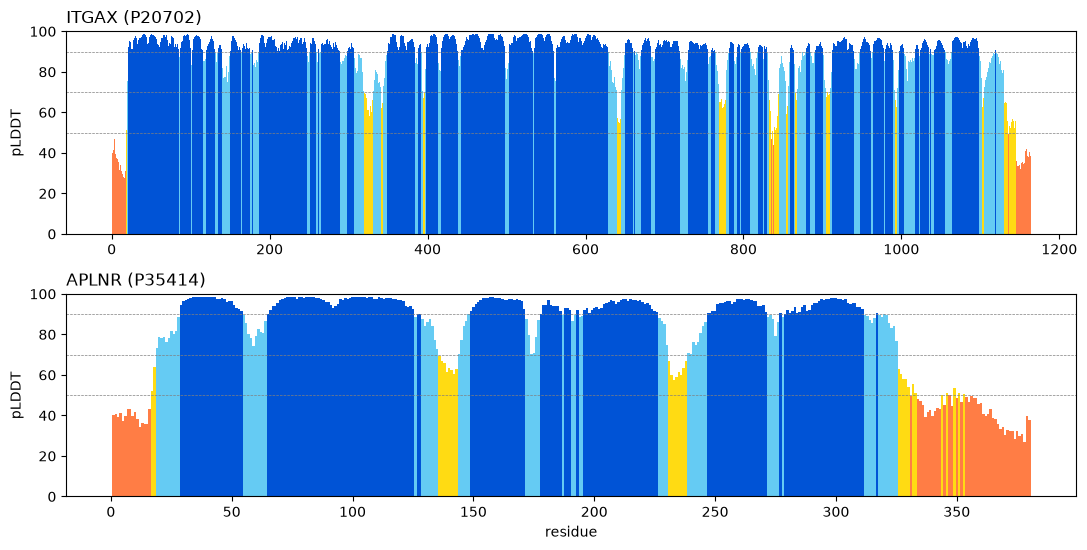

,gene,residues,mean_pLDDT,pct_above_90,pct_below_50,disordered_stretches
0,ITGAX,1163,88.0,65.3,3.4,"1-18, 1145-1163"
1,APLNR,380,81.7,56.8,15.5,"1-16, 334-343, 354-380"


In [4]:
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(11, 2.8 * len(TARGETS)), squeeze=False)
for ax, gene in zip(axes[:, 0], TARGETS):
    c = ca[gene]
    ax.bar(c.resnum, c.b, color=c.b.apply(band).map(BAND_COLOUR), width=1.0)
    for y in (50, 70, 90): ax.axhline(y, color="grey", lw=0.5, ls="--")
    ax.set_ylim(0, 100); ax.set_ylabel("pLDDT"); ax.set_title(f"{gene} ({TARGETS[gene]})", loc="left")
axes[-1, 0].set_xlabel("residue"); plt.tight_layout(); plt.show()

# TODO: one row per target with columns gene, residues, mean_pLDDT, pct_above_90, pct_below_50, disordered_stretches
plddt_summary = pd.DataFrame([{
    "gene": g, "residues": len(ca[g]),
    "mean_pLDDT": round(ca[g].b.mean(), 1),
    "pct_above_90": round((ca[g].b > 90).mean() * 100, 1),
    "pct_below_50": round((ca[g].b < 50).mean() * 100, 1),
    "disordered_stretches": runs_below(ca[g].b.values, ca[g].resnum.values),
} for g in TARGETS])
require(plddt_summary=plddt_summary)
plddt_summary

## Step 4 · Read PAE and find domains

Heatmaps are provided. **TODO:** run `find_domains` for each target, and for any target with two or more domains compute the **mean PAE between the first two domains** (low = arrangement confident, high = uncertain).

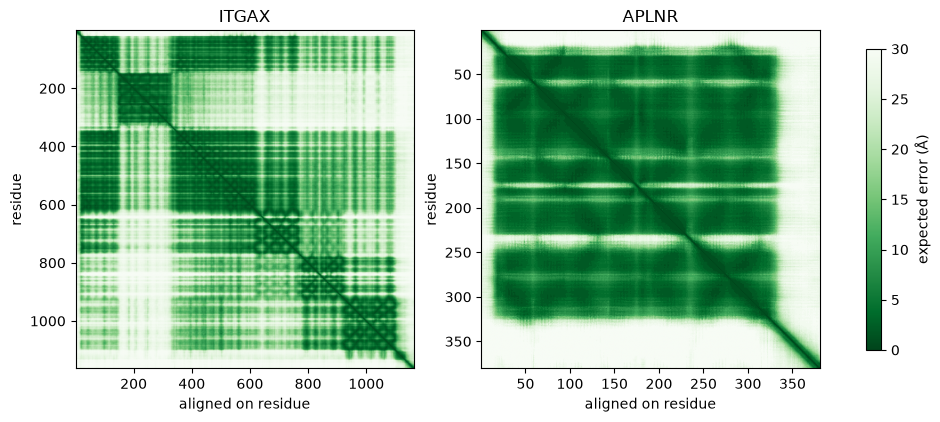


ITGAX: 1 confident domain(s); mean PAE between domains 1 and 2: nan Å
 start  end  confident_residues
    20 1130                1054

APLNR: 1 confident domain(s); mean PAE between domains 1 and 2: nan Å
 start  end  confident_residues
    19  325                 291


In [5]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(6 * len(TARGETS), 4.6), squeeze=False)
for ax, gene in zip(axes[0], TARGETS):
    n = pae[gene].shape[0]
    im = ax.imshow(pae[gene], cmap="Greens_r", vmin=0, vmax=30, extent=[0.5, n + 0.5, n + 0.5, 0.5])
    ax.set_title(gene); ax.set_xlabel("aligned on residue"); ax.set_ylabel("residue")
plt.colorbar(im, ax=axes, label="expected error (Å)", shrink=0.85); plt.show()

domains, inter_pae = {}, {}
# TODO: fill domains[gene] with find_domains(...) and inter_pae[gene] with the mean PAE between
#       domain 1 and domain 2 (np.nan if fewer than two domains)
for g in TARGETS:
    domains[g] = find_domains(pae[g], ca[g].b.values)
    if len(domains[g]) >= 2:
        d1, d2 = domains[g].iloc[0], domains[g].iloc[1]
        a = np.arange(d1.start - 1, d1.end); b = np.arange(d2.start - 1, d2.end)
        # both directions: aligned on domain 1 looking at domain 2, and the reverse
        inter_pae[g] = round(float((pae[g][np.ix_(a, b)].mean() + pae[g][np.ix_(b, a)].mean()) / 2), 1)
    else:
        inter_pae[g] = np.nan
for g in TARGETS:
    require(domains=domains[g], inter_pae=inter_pae[g])
    print(f"\n{g}: {len(domains[g])} confident domain(s); mean PAE between domains 1 and 2: {inter_pae[g]} Å")
    print(domains[g].to_string(index=False))

**In your report:** which regions would you trust for pocket analysis? Use the decision table (lecture slide 12).

## Step 5 · Compare with an experimental structure

For each target with a PDB entry: pair residues **by sequence alignment** (numbering often differs), superimpose on **identical, confident** pairs (pLDDT ≥ 70), and report the RMSD. If the target has two or more domains with high PAE between them, also report RMSD **per domain**.

In [6]:
comparison, deviation, exp_map = {}, {}, {}
for gene, entry in PDB.items():
    if entry is None:
        print(f"{gene}: no experimental structure; assess on confidence alone (say so in your report).")
        comparison[gene] = {"pdb_id": "none", "rmsd_confident": np.nan, "pairs_used": 0}
        continue
    pdb_id, chain = entry
    xt = read_pdb(download(f"https://files.rcsb.org/download/{pdb_id}.pdb", STRUCT / f"{pdb_id}.pdb"), chain=chain)
    xca, aca = ca_table(xt), ca[gene]
    pairs = global_align("".join(aca.aa), "".join(xca.aa))
    exp_map[gene] = {(xca.resnum[j], xca.icode[j]): aca.resnum[i] for i, j in pairs}   # PDB -> UniProt numbering
    A, X = aca[["x", "y", "z"]].to_numpy(), xca[["x", "y", "z"]].to_numpy()

    # TODO: keep only pairs where the amino acids match AND the AlphaFold pLDDT is >= 70,
    #       superimpose with kabsch, and store the RMSD
    use = [(i, j) for i, j in pairs if aca.aa[i] == xca.aa[j] and aca.b[i] >= 70]
    R, t, rmsd = kabsch(A[[i for i, _ in use]], X[[j for _, j in use]])
    require(use=use, rmsd=rmsd)
    moved = A @ R + t
    deviation[gene] = pd.Series({aca.resnum[i]: float(np.linalg.norm(moved[i] - X[j])) for i, j in use})
    comparison[gene] = {"pdb_id": pdb_id, "rmsd_confident": round(rmsd, 2), "pairs_used": len(use)}
    print(f"{gene} vs {pdb_id} chain {chain}: {len(pairs)} aligned pairs, {len(use)} identical and confident; RMSD {rmsd:.2f} Å")

    # Per-domain RMSD when the arrangement between domains is uncertain
    if len(domains[gene]) >= 2 and inter_pae[gene] > 10:
        for k, d in domains[gene].iterrows():
            sub = [(i, j) for i, j in use if d.start <= aca.resnum[i] <= d.end]
            if len(sub) >= 10:
                print(f"   domain {k + 1} ({d.start}-{d.end}): RMSD {kabsch(A[[i for i, _ in sub]], X[[j for _, j in sub]])[2]:.2f} Å over {len(sub)} residues")

ITGAX vs 4NEH chain A: 1084 aligned pairs, 1020 identical and confident; RMSD 0.86 Å
APLNR vs 7SUS chain A: 306 aligned pairs, 271 identical and confident; RMSD 2.83 Å


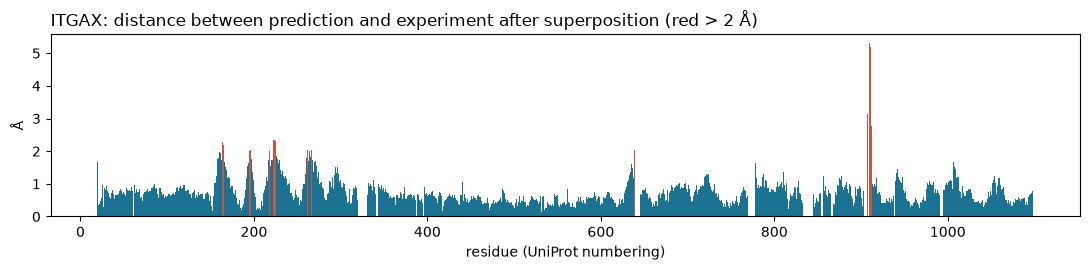

ITGAX: residues that differ most: 910 (5.3 Å), 911 (5.2 Å), 907 (3.1 Å), 912 (2.8 Å), 224 (2.3 Å), 223 (2.3 Å)


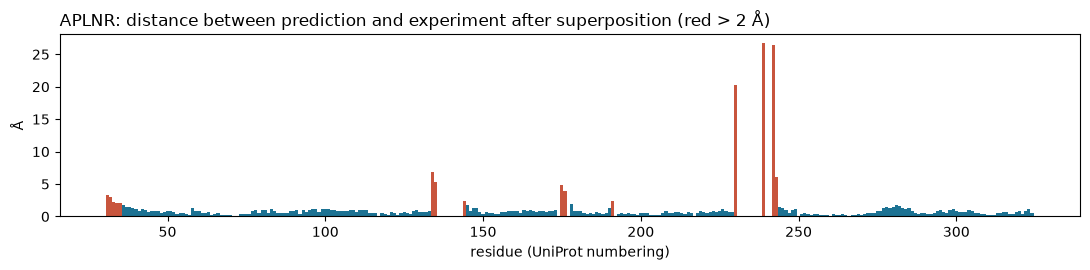

APLNR: residues that differ most: 239 (26.7 Å), 242 (26.5 Å), 230 (20.3 Å), 134 (6.9 Å), 243 (6.0 Å), 135 (5.3 Å)


In [7]:
for gene, dev in deviation.items():
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.bar(dev.index, dev.values, color=["#C8553D" if d > 2 else "#1C7293" for d in dev.values], width=1.0)
    ax.set_title(f"{gene}: distance between prediction and experiment after superposition (red > 2 Å)", loc="left")
    ax.set_xlabel("residue (UniProt numbering)"); ax.set_ylabel("Å"); plt.tight_layout(); plt.show()
    print(f"{gene}: residues that differ most:", ", ".join(f"{r} ({v:.1f} Å)" for r, v in dev.nlargest(6).items()))

### Step 5 extra · ITGAX per domain

At the default cut-off (PAE < 8 Å) the domain finder links all of ITGAX into one block, so the cell above does not split it. The heatmap disagrees: the I domain and the legs sit in pale blocks against the rest. Single linkage only needs a chain of a few low-PAE pairs to merge two domains, so I read the block averages directly. But one rigid fit over the whole ectodomain gives a large RMSD, which is the lab's warning sign. Here I fit each structural region of ITGAX separately (UniProt numbering): the β-propeller (20–147 and 337–480, with the I domain inserted between them), the I domain (148–336), and the thigh and calf "leg" domains (481–1101). I also run the domain finder at a stricter cut-off to see whether PAE separates the head from the legs, and repeat the fits against an earlier, lower-resolution crystal of the same ectodomain (3K6S, 3.5 Å) for contrast.

In [8]:
g = "ITGAX"
for cut in (4, 8):
    d = find_domains(pae[g], ca[g].b.values, pae_cut=cut)
    print(f"PAE < {cut} Å: " + "; ".join(f"{r.start}-{r.end} ({r.confident_residues})" for r in d.itertuples()))

# The single-linkage finder can chain domains together through a few low-PAE pairs, so read the blocks directly
def block_pae(a, b):
    A = np.r_[tuple(slice(x - 1, y) for x, y in a)]; B = np.r_[tuple(slice(x - 1, y) for x, y in b)]
    return round(float((pae[g][np.ix_(A, B)].mean() + pae[g][np.ix_(B, A)].mean()) / 2), 1)
prop, idom, head, legs = [(20, 147), (337, 480)], [(148, 336)], [(20, 480)], [(621, 1101)]
print(f"mean PAE within the propeller {block_pae(prop, prop)} Å, within the I domain {block_pae(idom, idom)} Å")
print(f"mean PAE I domain <-> propeller {block_pae(idom, prop)} Å; headpiece <-> calf legs (621-1101) {block_pae(head, legs)} Å")

regions = {"beta-propeller (20-147, 337-480)": lambda r: 20 <= r <= 147 or 337 <= r <= 480,
           "I domain (148-336)": lambda r: 148 <= r <= 336,
           "I domain core (148-320)": lambda r: 148 <= r <= 320,
           "thigh + calf legs (481-1101)": lambda r: 481 <= r <= 1101,
           "whole chain": lambda r: True}
rows = []
for pdb_id in ("4NEH", "3K6S"):     # 3K6S: an earlier, 3.5 A crystal of the same ectodomain, for contrast
    xt = read_pdb(download(f"https://files.rcsb.org/download/{pdb_id}.pdb", STRUCT / f"{pdb_id}.pdb"), chain="A")
    xca, aca = ca_table(xt), ca[g]
    pairs = global_align("".join(aca.aa), "".join(xca.aa))
    use = [(i, j) for i, j in pairs if aca.aa[i] == xca.aa[j] and aca.b[i] >= 70]
    A, X = aca[["x", "y", "z"]].to_numpy(), xca[["x", "y", "z"]].to_numpy()
    for name, inside in regions.items():
        sub = [(i, j) for i, j in use if inside(aca.resnum[i])]
        rows.append({"pdb": pdb_id, "region": name, "residues": len(sub),
                     "RMSD_A": round(kabsch(A[[i for i, _ in sub]], X[[j for _, j in sub]])[2], 2)})
itgax_regions = pd.DataFrame(rows).pivot(index="region", columns="pdb", values="RMSD_A")[["4NEH", "3K6S"]]
itgax_regions

PAE < 4 Å: 20-769 (728); 778-1101 (299); 1105-1130 (26)
PAE < 8 Å: 20-1130 (1054)
mean PAE within the propeller 4.7 Å, within the I domain 4.8 Å
mean PAE I domain <-> propeller 17.5 Å; headpiece <-> calf legs (621-1101) 20.5 Å


pdb,4NEH,3K6S
region,,
I domain (148-336),0.32,4.23
I domain core (148-320),0.27,1.82
"beta-propeller (20-147, 337-480)",0.25,1.77
thigh + calf legs (481-1101),0.64,3.85
whole chain,0.86,8.53


### Step 5 extra · APLNR without the engineered insert

In 7SUS, receptor residues 230–242 (intracellular loop 3) were replaced by a rubredoxin domain to help crystallisation; the PDB numbers it 1001–1054. The global alignment still pairs a few of those rubredoxin residues with APLNR residues that happen to have the same amino acid, which is where the 20–27 Å "deviations" come from. Those pairs compare APLNR with a different protein. Here I drop them (PDB residue number ≥ 1000) and recompute.

In [9]:
g = "APLNR"
xt = read_pdb(STRUCT / f"{PDB[g][0]}.pdb", chain=PDB[g][1]); xca, aca = ca_table(xt), ca[g]
pairs = global_align("".join(aca.aa), "".join(xca.aa))
use = [(i, j) for i, j in pairs if aca.aa[i] == xca.aa[j] and aca.b[i] >= 70]
fusion = [(i, j) for i, j in use if xca.resnum[j] >= 1000]
clean = [(i, j) for i, j in use if xca.resnum[j] < 1000]
A, X = aca[["x", "y", "z"]].to_numpy(), xca[["x", "y", "z"]].to_numpy()
R, t, rmsd_clean = kabsch(A[[i for i, _ in clean]], X[[j for _, j in clean]])
print(f"pairs to the rubredoxin insert: {len(fusion)} (APLNR residues {[int(aca.resnum[i]) for i, _ in fusion]})")
print(f"RMSD without them: {rmsd_clean:.2f} Å over {len(clean)} residues")
dev = pd.Series({int(aca.resnum[i]): float(np.linalg.norm(A[i] @ R + t - X[j])) for i, j in clean})
print("largest remaining differences:", ", ".join(f"{r} ({v:.1f} Å)" for r, v in dev.nlargest(6).items()))
print(f"residues more than 2 Å apart: {(dev > 2).sum()} of {len(dev)}")
deviation["APLNR"] = dev
comparison["APLNR"]["rmsd_confident"] = round(rmsd_clean, 2)   # the CSV reports the insert-free RMSD

# Does the real drug fit the predicted pocket? Fit on the site neighbourhood, move 8EH across, count clashes
at7 = read_pdb(STRUCT / "7SUS.pdb", chain="A"); lig = at7[(at7.record == "HETATM") & (at7.resname == "8EH")]
L0 = lig[["x", "y", "z"]].to_numpy()
near = [(i, j) for i, j in clean if np.linalg.norm(X[j] - L0, axis=1).min() < 10]
R2, t2, r2 = kabsch(X[[j for _, j in near]], A[[i for i, _ in near]])
L = L0 @ R2 + t2
H = atoms[g][["x", "y", "z"]].to_numpy(); d = np.linalg.norm(L[:, None] - H[None], axis=2)
bad = atoms[g].iloc[np.where(d.min(0) < 2.2)[0]].drop_duplicates("resnum")
print(f"\n8EH placed in the AlphaFold model (site fit {r2:.2f} Å over {len(near)} residues): "
      f"{(d.min(1) < 2.2).sum()}/{len(L)} ligand atoms closer than 2.2 Å to the model, closest {d.min():.2f} Å; "
      f"clashing residues: {', '.join(f'{a}{n}' for a, n in zip(bad.resname, bad.resnum))}")
site_plddt = ca[g].set_index("resnum").b.reindex(sorted(set(atoms[g].resnum[d.min(0) < 4.5]))).mean()
print(f"mean pLDDT of model residues within 4.5 Å of the placed drug: {site_plddt:.1f}")

pairs to the rubredoxin insert: 3 (APLNR residues [230, 239, 242])
RMSD without them: 1.11 Å over 268 residues
largest remaining differences: 134 (6.8 Å), 243 (6.3 Å), 135 (5.1 Å), 175 (4.9 Å), 176 (4.0 Å), 31 (3.3 Å)
residues more than 2 Å apart: 13 of 268

8EH placed in the AlphaFold model (site fit 0.60 Å over 68 residues): 6/37 ligand atoms closer than 2.2 Å to the model, closest 0.88 Å; clashing residues: TRP85, TYR299
mean pLDDT of model residues within 4.5 Å of the placed drug: 95.1


## Step 6 · Detect and filter pockets

**TODO:** for each pocket, compute the mean pLDDT of the lining residues and the mean PAE among them, then apply the rules: **reject** if mean pLDDT < 70; **suspect** if PAE among the lining residues > 10 Å; otherwise **keep**. Show the top five by druggability score. Every pocket is kept (with its **rank** by score) for the ligand-site check below.

In [10]:
if shutil.which("fpocket") is None:
    raise RuntimeError("fpocket not found. Mac/Linux: conda install -c conda-forge fpocket, then restart the kernel. "
                       "Windows: run this notebook on the Explorer cluster.")
top_pockets, all_pockets = {}, {}
for gene in TARGETS:
    pk = run_fpocket(files[gene][0])
    plddt = ca[gene].set_index("resnum").b
    # TODO: add columns mean_pLDDT, PAE_within and verdict to pk
    pk["mean_pLDDT"] = pk.lining_residues.apply(lambda r: round(float(plddt.reindex(r).mean()), 1))
    pk["PAE_within"] = pk.lining_residues.apply(
        lambda r: round(float(pae[gene][np.ix_(np.array(r) - 1, np.array(r) - 1)].mean()), 1))
    pk["verdict"] = np.where(pk.mean_pLDDT < 70, "reject: low confidence",
                    np.where(pk.PAE_within > 10, "suspect: lining not placed together", "keep"))
    require(verdict=pk["verdict"].iloc[0])
    pk["rank"] = pk["Druggability Score"].rank(ascending=False, method="first").astype(int)
    all_pockets[gene] = pk
    top_pockets[gene] = pk.sort_values("Druggability Score", ascending=False).head(5)
    print(f"\n{gene}: top five pockets by druggability score")
    print(top_pockets[gene].drop(columns="lining_residues").to_string(index=False))


ITGAX: top five pockets by druggability score
 pocket  Druggability Score  Volume  mean_pLDDT  PAE_within verdict  rank
      4               0.489 284.283        89.0         2.6    keep     1
     79               0.470 926.675        89.3         3.2    keep     2
      3               0.098 516.986        92.2         1.8    keep     3
     26               0.093 433.556        90.3         2.6    keep     4
     71               0.083 371.267        92.7         1.9    keep     5

APLNR: top five pockets by druggability score
 pocket  Druggability Score   Volume  mean_pLDDT  PAE_within verdict  rank
      9               0.304  427.668        94.2         2.0    keep     1
     22               0.182  363.658        91.2         2.2    keep     2
     10               0.111  950.893        82.0         4.3    keep     3
      2               0.015 1761.466        94.0         3.1    keep     4
      1               0.010  713.934        78.4         5.5    keep     5


### Ligand-site check *(provided)*

**If your experimental structure has a ligand bound,** the next cell takes **each** bound ligand in turn, finds the protein residues within 4.5 Å of it, converts them to UniProt numbering using your Step 5 alignment, and searches **every** pocket, not just the top five. For each ligand it reports how much of the site your best kept pocket covers, and which pocket covers it best, with that pocket's rank, score and verdict.

**In your report:** is your best **kept** pocket where the ligand sits? If there are several copies of a ligand, which one is in the functional site? If not, which pocket is, how does it rank, and why might fpocket score a real binding site low? (Large, open or polar sites, such as protease clefts, often score poorly.)

*Not counted as ligands:* water, metal ions, common crystallization additives (sulfate, glycerol and similar), and peptide or nucleic-acid partners deposited as a separate protein or DNA chain.

In [11]:
IGNORE_HET = {"HOH", "WAT", "DOD", "SO4", "PO4", "GOL", "EDO", "PEG", "PG4", "PGE", "1PE", "ACT", "FMT", "DMS",
              "MPD", "BME", "TRS", "EPE", "MES", "IMD", "CL", "NA", "K", "MG", "CA", "ZN", "MN", "FE", "CU", "CO",
              "NI", "CD", "HG", "IOD", "BR", "NO3", "NH4", "SCN", "UNX"}

def ligand_sites(pdb_path, chain, cutoff=4.5, min_atoms=6):
    """For each small-molecule ligand touching `chain`: the (resnum, icode) of chain residues within `cutoff` Å."""
    at = read_pdb(pdb_path)
    het = at[(at.record == "HETATM") & ~at.resname.isin(IGNORE_HET)]
    het = het[het.groupby(["chain", "resname", "resnum"]).x.transform("size") >= min_atoms]   # drop ions / tiny additives
    prot = at[(at.record == "ATOM") & (at.chain == chain)]
    sites = {}
    for (c, name, num), lig in het.groupby(["chain", "resname", "resnum"]):
        d = np.linalg.norm(prot[["x", "y", "z"]].to_numpy()[:, None] - lig[["x", "y", "z"]].to_numpy()[None], axis=2)
        near = (d < cutoff).any(1)
        if near.any():
            sites[f"{name} {c}{num}"] = set(zip(prot.resnum[near], prot.icode[near]))
    return sites

ligand_pockets = {}
for gene, entry in PDB.items():
    if entry is None:
        print(f"{gene}: no experimental structure, so no ligand-site check.\n"); continue
    pdb_id, chain = entry
    sites = ligand_sites(STRUCT / f"{pdb_id}.pdb", chain)
    if not sites:
        print(f"{gene}: {pdb_id} chain {chain} has no bound small-molecule ligand to check against.\n"); continue
    pk = all_pockets[gene]
    kept = pk[pk.verdict == "keep"].sort_values("Druggability Score", ascending=False)
    best = kept.iloc[0] if len(kept) else None
    rows = []
    for lig, contacts in sites.items():
        site = sorted({exp_map[gene][k] for k in contacts if k in exp_map[gene]})   # UniProt numbering
        if not site:
            print(f"  {lig}: its contact residues are not in the aligned region; skipped"); continue
        cover = pk.lining_residues.apply(lambda r: len(set(r) & set(site)) / len(site))
        top = pk.loc[cover.idxmax()]
        rows.append({"ligand": lig, "site_residues": len(site),
                     "best_kept_pocket_covers": round(float(cover[best.name]), 2) if best is not None else np.nan,
                     "site_pocket": int(top.pocket), "site_pocket_rank": int(top["rank"]),
                     "site_pocket_score": round(top["Druggability Score"], 3), "site_pocket_verdict": top.verdict,
                     "site_pocket_covers": round(float(cover.max()), 2), "residues": ", ".join(map(str, site))})
    ligand_pockets[gene] = pd.DataFrame(rows)
    print(f"{gene} vs {pdb_id} chain {chain}  |  best kept pocket: "
          + (f"{int(best.pocket)} (score {best['Druggability Score']:.3f}, rank {int(best['rank'])})" if best is not None else "none"))
    print(ligand_pockets[gene].drop(columns="residues").to_string(index=False))
    for r in rows:
        print(f"  {r['ligand']} site (UniProt numbering): {r['residues']}")
    print()


ITGAX vs 4NEH chain A  |  best kept pocket: 4 (score 0.489, rank 1)
   ligand  site_residues  best_kept_pocket_covers  site_pocket  site_pocket_rank  site_pocket_score site_pocket_verdict  site_pocket_covers
NAG A1119              5                      0.0           18                16              0.006                keep                0.40
   NAG C1              5                      0.0           14                18              0.005                keep                0.40
   NAG C2              1                      0.0           14                18              0.005                keep                1.00
   NAG D1              5                      0.0           21                55              0.000                keep                0.60
   BMA E3              1                      0.0           47                14              0.008                keep                1.00
   MAN E4              3                      0.0           47                14            

### Step 6 extra · ITGAX allosteric-site test with a borrowed ligand

ITGAX's 4NEH entry has no drug-like ligand, so the provided check can only report glycans (NAG). To test the Module 3 question directly, I borrow the ligand from the related integrin LFA-1 (ITGAL): **1CQP** is the LFA-1 I domain with **lovastatin** bound in its allosteric pocket under the C-terminal α7 helix. I superimpose that I domain on ITGAX's I domain (BLOSUM62 local alignment, since the two are only about 35% identical; core residues 150–315), move the ligand across, and ask (a) does it clash with the protein and (b) does any fpocket pocket hold it. As a positive control I run the same check on the LFA-1 crystal itself with the ligand removed.

In [12]:
def place_ligand(target_pdb, target_ca, donor_pdb, donor_chain, ligand, region=(150, 315)):
    """Superimpose the donor domain on the target by sequence alignment and return the moved ligand atoms."""
    dn = read_pdb(download(f"https://files.rcsb.org/download/{donor_pdb}.pdb", STRUCT / f"{donor_pdb}.pdb"), chain=donor_chain)
    dca = ca_table(dn)
    sub = target_ca[(target_ca.resnum >= region[0]) & (target_ca.resnum <= region[1])].reset_index(drop=True)
    from Bio.Align import PairwiseAligner, substitution_matrices   # BLOSUM62 aligns the 35%-identical homologues better
    al = PairwiseAligner(mode="local", substitution_matrix=substitution_matrices.load("BLOSUM62"),
                         open_gap_score=-10, extend_gap_score=-0.5)
    aln = al.align("".join(sub.aa), "".join(dca.aa))[0]
    pr = [(i, j) for (a0, a1), (b0, b1) in zip(*aln.aligned) for i, j in zip(range(a0, a1), range(b0, b1))]
    P = dca[["x", "y", "z"]].to_numpy()[[j for _, j in pr]]; Q = sub[["x", "y", "z"]].to_numpy()[[i for i, _ in pr]]
    R, t, r = kabsch(P, Q)
    lig = dn[(dn.record == "HETATM") & (dn.resname == ligand)][["x", "y", "z"]].to_numpy() @ R + t
    return lig, r, len(pr)

def ligand_fit(protein_atoms, pocket_dir, pockets, lig):
    H = protein_atoms[["x", "y", "z"]].to_numpy()
    clash = int((np.linalg.norm(lig[:, None] - H[None], axis=2).min(1) < 2.2).sum())
    best = (None, 0.0)
    for p in pockets.pocket:
        V = read_pdb(pocket_dir / "pockets" / f"pocket{p}_vert.pqr")[["x", "y", "z"]].to_numpy()
        f = float((np.linalg.norm(lig[:, None] - V[None], axis=2).min(1) < 3).mean())
        if f > best[1]: best = (p, f)
    return clash, best

# Positive control: the LFA-1 crystal with lovastatin removed
lfa = read_pdb(download("https://files.rcsb.org/download/1CQP.pdb", STRUCT / "1CQP.pdb"), chain="A")
apo = STRUCT / "1CQP_A_apo.pdb"
with open(STRUCT / "1CQP.pdb") as fin, open(apo, "w") as fout:
    fout.writelines(l for l in fin if l.startswith("ATOM") and l[21] == "A")
lfa_pk = run_fpocket(apo); lov = lfa[(lfa.record == "HETATM") & (lfa.resname == "803")][["x", "y", "z"]].to_numpy()
clash, (p, f) = ligand_fit(read_pdb(apo), STRUCT / "1CQP_A_apo_out", lfa_pk, lov)
s = lfa_pk.set_index("pocket").loc[p, "Druggability Score"]
print(f"LFA-1 crystal (control): lovastatin clashes {clash}/{len(lov)} atoms; pocket {p} (score {s:.2f}) holds {f:.0%} of it")

# ITGAX: the AlphaFold model and the experimental I domain (1N3Y, 1.65 A)
lig, r, n = place_ligand(files["ITGAX"][0], ca["ITGAX"], "1CQP", "A", "803")
clash, (p, f) = ligand_fit(atoms["ITGAX"], STRUCT / f"{files['ITGAX'][0].stem}_out", all_pockets["ITGAX"], lig)
print(f"ITGAX AlphaFold: I-domain fit {r:.2f} Å over {n} pairs; lovastatin clashes {clash}/{len(lig)} atoms; "
      + (f"best pocket {p} holds {f:.0%}" if p else "no pocket holds it"))
n3y = read_pdb(download("https://files.rcsb.org/download/1N3Y.pdb", STRUCT / "1N3Y.pdb"), chain="A")
n3y_file = STRUCT / "1N3Y_A.pdb"
with open(STRUCT / "1N3Y.pdb") as fin, open(n3y_file, "w") as fout:
    fout.writelines(l for l in fin if l.startswith("ATOM") and l[21] == "A")
n3y_pk = run_fpocket(n3y_file)
lig, r, n = place_ligand(n3y_file, ca_table(n3y), "1CQP", "A", "803")
clash, (p, f) = ligand_fit(read_pdb(n3y_file), STRUCT / "1N3Y_A_out", n3y_pk, lig)
print(f"ITGAX crystal 1N3Y: I-domain fit {r:.2f} Å over {n} pairs; lovastatin clashes {clash}/{len(lig)} atoms; "
      + (f"best pocket {p} holds {f:.0%} (score {n3y_pk.set_index('pocket').loc[p, 'Druggability Score']:.3f})" if p else "no pocket holds it"))

# Are ITGAX's two top-scoring (propeller) pockets open surfaces, or covered by beta2 or sugar in the 4NEH heterodimer?
x4 = read_pdb(STRUCT / "4NEH.pdb"); xa = ca_table(x4[x4.chain == "A"]); aca = ca["ITGAX"]
pr = [(i, j) for i, j in global_align("".join(aca.aa), "".join(xa.aa)) if aca.aa[i] == xa.aa[j] and aca.b[i] >= 70]
R, t, _ = kabsch(aca[["x", "y", "z"]].to_numpy()[[i for i, _ in pr]], xa[["x", "y", "z"]].to_numpy()[[j for _, j in pr]])
beta2 = x4[(x4.chain == "B") & (x4.record == "ATOM")][["x", "y", "z"]].to_numpy()
sugar = x4[x4.resname.isin(["NAG", "MAN", "BMA", "FUC"])][["x", "y", "z"]].to_numpy()
seq = "".join(aca.aa)
sequons = {i + 1 for i in range(len(seq) - 2) if seq[i] == "N" and seq[i + 1] != "P" and seq[i + 2] in "ST"}
print()
for _, q in top_pockets["ITGAX"].head(2).iterrows():
    V = read_pdb(STRUCT / f"{files['ITGAX'][0].stem}_out" / "pockets" / f"pocket{q.pocket}_vert.pqr")[["x", "y", "z"]].to_numpy() @ R + t
    print(f"pocket {q.pocket} (score {q['Druggability Score']:.2f}, residues {min(q.lining_residues)}-{max(q.lining_residues)}): "
          f"closest beta2 atom {np.linalg.norm(V[:, None] - beta2[None], axis=2).min():.1f} Å, closest sugar {np.linalg.norm(V[:, None] - sugar[None], axis=2).min():.1f} Å, "
          f"glycosylation sequons in lining: {sorted(sequons & set(q.lining_residues)) or 'none'}")

LFA-1 crystal (control): lovastatin clashes 0/29 atoms; pocket 1 (score 0.44) holds 72% of it


ITGAX AlphaFold: I-domain fit 2.43 Å over 155 pairs; lovastatin clashes 22/29 atoms; best pocket 9 holds 3%
ITGAX crystal 1N3Y: I-domain fit 2.72 Å over 157 pairs; lovastatin clashes 27/29 atoms; best pocket 5 holds 21% (score 0.002)



pocket 4 (score 0.49, residues 84-143): closest beta2 atom 12.2 Å, closest sugar 11.6 Å, glycosylation sequons in lining: none
pocket 79 (score 0.47, residues 104-388): closest beta2 atom 13.7 Å, closest sugar 11.4 Å, glycosylation sequons in lining: [385]


## Step 7 · Make a druggability call and export the summary

Choose one call per target: **"Structure supports a small-molecule pocket"**, **"Possible but uncertain"**, or **"No confident pocket: consider another modality"**. Justify it in your report.

In [13]:
CALLS = {
    "ITGAX": "Possible but uncertain",
    "APLNR": "Structure supports a small-molecule pocket",
}
assert set(CALLS) == set(TARGETS), "Give a call for every target"

rows = []
for g, acc in TARGETS.items():
    kept = top_pockets[g][top_pockets[g].verdict == "keep"]
    rows.append({"gene": g, "uniprot": acc, "module2_rank": TARGET_INFO[g]["module2_rank"],
                 "mean_pLDDT": plddt_summary.set_index("gene").loc[g, "mean_pLDDT"],
                 "pct_below_50": plddt_summary.set_index("gene").loc[g, "pct_below_50"],
                 "n_domains": len(domains[g]), "inter_domain_PAE": inter_pae[g],
                 "pdb_id": comparison[g]["pdb_id"], "rmsd_confident": comparison[g]["rmsd_confident"],
                 "best_pocket_score": round(kept["Druggability Score"].max(), 3) if len(kept) else np.nan,
                 "best_pocket_verdict": "keep" if len(kept) else top_pockets[g].verdict.iloc[0],
                 "druggability_call": CALLS[g]})
summary = pd.DataFrame(rows)
out_file = f"structure_assessment_{DISEASE}.csv"
summary.to_csv(out_file, index=False)
print("Wrote", out_file)
summary

Wrote structure_assessment_ad.csv


,gene,uniprot,module2_rank,mean_pLDDT,pct_below_50,n_domains,inter_domain_PAE,pdb_id,rmsd_confident,best_pocket_score,best_pocket_verdict,druggability_call
0,ITGAX,P20702,6,88.0,3.4,1,NaN,4NEH,0.86,0.489,keep,Possible but uncertain
1,APLNR,P35414,10,81.7,15.5,1,NaN,7SUS,1.11,0.304,keep,Structure supports a small-molecule pocket


## Step 8 · Anchor check: p53

From your **lab Part 2** results, write one short paragraph in your report: the p53 RMSD to 1TUP over confident residues, which hotspots are zinc ligands and which touch DNA, and what that says about your Module 3 variant scores. No code needed here.

## Step 9 · Report (3–4 pages, the 40%)

Answer the five questions on the assignment sheet (confidence, validation, druggability, integration, limits), using the tables and plots above. Submit the notebook, `structure_assessment_<disease>.csv`, your report (PDF) and a README, and add `structures/` to `.gitignore`.